# Heart Disease Prediction Using Machine Learning

## 1. Project Objective

The objective of this project is to develop a machine learning classification model that predicts whether a patient is likely to have heart disease based on medical and demographic features.

### Problem Type

**Binary Classification**

### Dataset

**Heart Disease Dataset**

### Target Variable

The dataset contains a target variable named `num`, which represents the presence and severity of heart disease.

For this project, after examining the target values, it will be converted into two classes:

* `0` → No heart disease
* `1` → Presence of heart disease


In [2]:
# Import libraries required for data analysis,
# visualization, preprocessing, and machine learning.

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Importing Required Libraries

The required Python libraries are imported for data analysis, visualization, data preprocessing, and machine learning.

* **Pandas** is used to load and manipulate the dataset.
* **NumPy** is used for numerical operations.
* **Matplotlib** and **Seaborn** are used to create visualizations for exploratory data analysis.
* **Scikit-learn** provides tools for splitting the data, preprocessing features, and building machine learning pipelines.

The successful execution of the code confirms that all required libraries have been imported.


In [3]:
# Load the Heart Disease dataset

df = pd.read_csv("heart_disease_uci.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [4]:
# Display the first five rows of the dataset

df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## 3. Loading the Dataset

The Heart Disease dataset is loaded into a Pandas DataFrame using the `read_csv()` function.

The `head()` function is then used to display the first five records. This helps us understand the structure of the dataset, identify the available features, and observe the type of values present in each column.


In [5]:
# Check the number of rows and columns in the dataset

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 920
Number of columns: 16


In [6]:
# Display information about the dataset,
# including column names, data types, and non-null values.

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 156.4+ KB


In [7]:
# Display all column names in the dataset

print("Columns in the dataset:")
print(df.columns.tolist())

Columns in the dataset:
['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


## 4. Understanding the Dataset

The dimensions of the dataset are examined using the `shape` attribute to determine the number of records and features.

The `info()` function is used to understand the structure of the dataset, including the data types and the number of non-null values in each column.

The column names are also displayed to identify the features available for building the machine learning model.

This step is important because understanding the structure and data types of the dataset helps us decide the appropriate data cleaning and preprocessing techniques.

In [8]:
# Check the number of missing values in each column

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


In [9]:
# Check for duplicate rows in the dataset

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [10]:
# Display statistical summary of numerical columns

df.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


## 5. Checking Missing Values, Duplicates and Statistics

Missing values are checked because incomplete records can affect machine learning model performance. The number of missing values in each column is calculated using the `isnull().sum()` method.

Duplicate rows are also checked because repeated records may introduce unnecessary bias during model training.

The `describe()` function is used to obtain statistical information about numerical features, including the count, mean, standard deviation, minimum, maximum, and quartile values.

Based on these results, appropriate data-cleaning and preprocessing techniques will be selected.

In [11]:
# Check the unique values in each column.
# This helps us understand categorical variables and
# identify columns that may not provide useful information.

for column in df.columns:
    print(f"\n{column}:")
    print(df[column].unique())


id:
[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108
 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126
 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144
 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162
 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179 180
 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197 198
 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215 216
 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233 234
 235 236 237 238 239 240 241 242 243 244 245 2

In [12]:
# Count the number of unique values in each column

unique_counts = df.nunique()

print("Number of unique values in each column:")
print(unique_counts)

Number of unique values in each column:
id          920
age          50
sex           2
dataset       4
cp            4
trestbps     61
chol        217
fbs           2
restecg       3
thalch      119
exang         2
oldpeak      53
slope         3
ca            4
thal          3
num           5
dtype: int64


In [13]:
# Check the distribution of the target variable

print("Target value counts:")
print(df["num"].value_counts().sort_index())

Target value counts:
num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64


## 6. Exploring Unique Values and Target Distribution

The unique values and number of unique values in each feature are examined to understand the structure of categorical and numerical variables.

The target variable `num` is also examined before converting it into a binary classification target. This ensures that the transformation is based on the actual values present in the dataset.

This analysis also helps identify identifier columns or columns with very little variation that may not provide useful information for prediction.

In [14]:
# Convert the original target variable into a binary target.
# 0 represents no heart disease.
# Values 1 to 4 represent the presence of heart disease.

df["target"] = (df["num"] > 0).astype(int)

print("Binary target distribution:")
print(df["target"].value_counts().sort_index())

Binary target distribution:
target
0    411
1    509
Name: count, dtype: int64


In [15]:
# Verify that the binary target was created correctly

print("Original target distribution:")
print(df["num"].value_counts().sort_index())

print("\nBinary target distribution:")
print(df["target"].value_counts().sort_index())

Original target distribution:
num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

Binary target distribution:
target
0    411
1    509
Name: count, dtype: int64


In [16]:
# Remove columns that should not be used as predictive features.
# 'id' is only an identifier.
# 'dataset' indicates the source of the record rather than a patient characteristic.
# 'num' is the original target and is replaced by the binary 'target'.

df_model = df.drop(columns=["id", "dataset", "num"])

print("Columns used for machine learning:")
print(df_model.columns.tolist())

Columns used for machine learning:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


## 7. Data Cleaning and Target Preparation

The original target variable `num` contains five values ranging from 0 to 4. Since the objective of this project is to predict whether heart disease is present or absent, the target is converted into a binary variable.

A value of 0 is mapped to no heart disease, while values from 1 to 4 are mapped to the presence of heart disease.

The `id` column is removed because it is only an identifier and does not represent a meaningful medical characteristic. The `dataset` column is also removed because it represents the source of the record rather than a patient feature.

The original `num` column is removed after creating the new binary `target` column to prevent target leakage.

In [17]:
# Separate the input features (X) and target variable (y)

X = df_model.drop(columns=["target"])
y = df_model["target"]

print("Features (X):", X.shape)
print("Target (y):", y.shape)

Features (X): (920, 13)
Target (y): (920,)


In [18]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']

Categorical features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


C:\Users\HP\AppData\Local\Temp\ipykernel_15136\859732398.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns.tolist()


In [19]:
# Display the data type of each feature

print(X.dtypes)

age           int64
sex             str
cp              str
trestbps    float64
chol        float64
fbs          object
restecg         str
thalch      float64
exang        object
oldpeak     float64
slope           str
ca          float64
thal            str
dtype: object


## 8. Identifying Feature Types

The input features and target variable are separated into `X` and `y`.

The features are then divided into numerical and categorical variables based on their data types.

Numerical features contain continuous or numerical measurements such as age, resting blood pressure, cholesterol, maximum heart rate, and oldpeak.

Categorical features represent categories or discrete values such as sex, chest-pain type, fasting blood sugar, resting ECG results, exercise-induced angina, slope, and thal.

This separation is necessary because numerical and categorical variables require different preprocessing techniques.

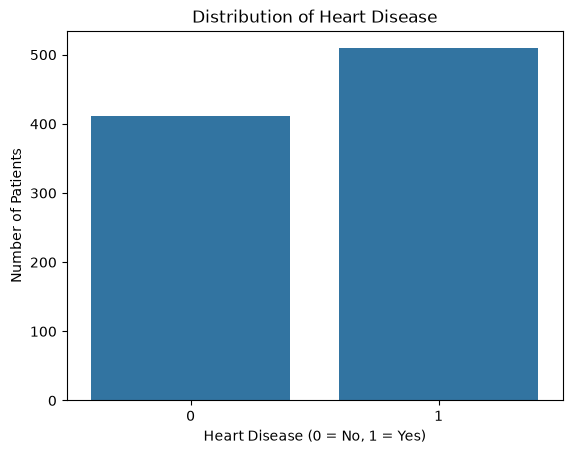

In [20]:
# Visualize the distribution of the binary target variable

sns.countplot(x="target", data=df_model)

plt.title("Distribution of Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

## 9. Exploratory Data Analysis (EDA)

### 9.1 Distribution of the Target Variable

The distribution of the target variable is visualized to understand the number of patients with and without heart disease.

- `0` represents patients without heart disease.
- `1` represents patients with heart disease.

The graph helps determine whether the target classes are balanced or highly imbalanced. The two classes are reasonably represented in this dataset, although the heart-disease class contains slightly more observations.

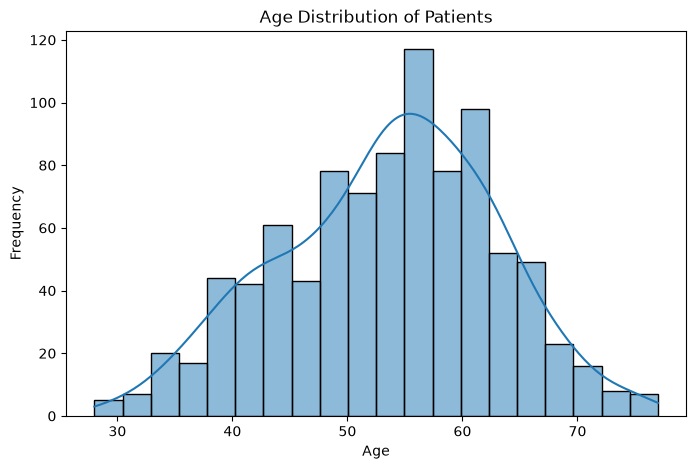

In [21]:
# Visualize the distribution of patient ages

plt.figure(figsize=(8, 5))

sns.histplot(data=df_model, x="age", bins=20, kde=True)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

### 9.2 Age Distribution

The age distribution is examined using a histogram. This visualization shows the age range of patients and identifies the age groups that occur most frequently in the dataset.

The KDE curve provides a smooth representation of the overall age distribution.

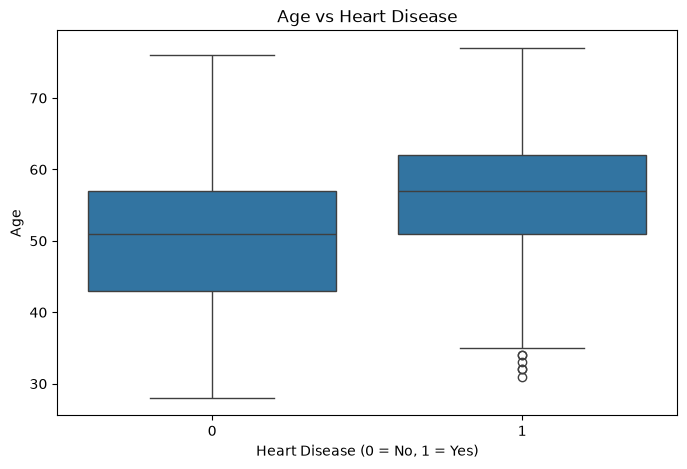

In [22]:
# Compare age distributions for patients with and without heart disease

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_model, x="target", y="age")

plt.title("Age vs Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

### 9.3 Age and Heart Disease

A boxplot is used to compare the age distribution of patients with and without heart disease.

This visualization helps determine whether age shows a noticeable relationship with the target variable. The median, spread, and possible outliers can also be compared between the two groups.

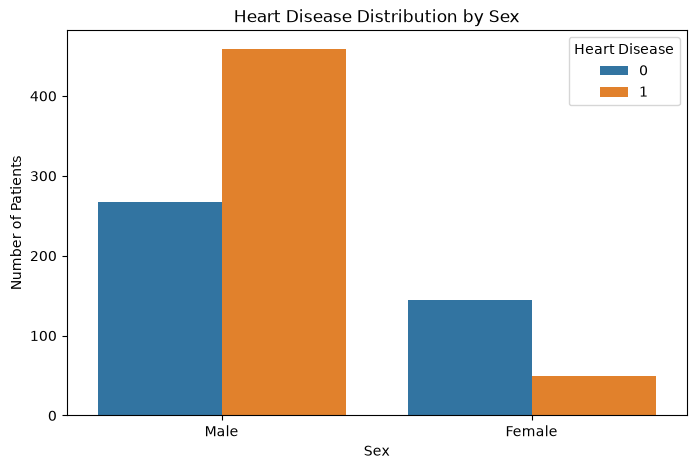

In [23]:
# Compare heart disease distribution across sex

plt.figure(figsize=(8, 5))

sns.countplot(data=df_model, x="sex", hue="target")

plt.title("Heart Disease Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Patients")
plt.legend(title="Heart Disease")

plt.show()

### 9.4 Sex and Heart Disease

The relationship between sex and heart disease is visualized using a count plot.

The plot compares the number of patients with and without heart disease across the different sex categories. This helps us understand whether the distribution of the target differs between these groups.

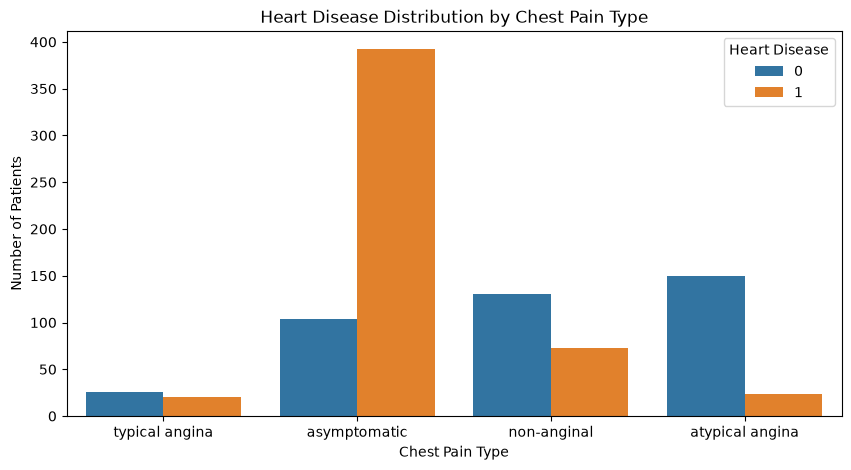

In [24]:
# Compare heart disease distribution across chest pain types

plt.figure(figsize=(10, 5))

sns.countplot(data=df_model, x="cp", hue="target")

plt.title("Heart Disease Distribution by Chest Pain Type")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")
plt.legend(title="Heart Disease")

plt.show()

### 9.5 Chest Pain Type and Heart Disease

The distribution of heart disease across different chest pain types is visualized.

Chest pain type is an important categorical feature because different types of chest pain may show different patterns between patients with and without heart disease.

The plot allows us to compare the target distribution across the available chest pain categories.

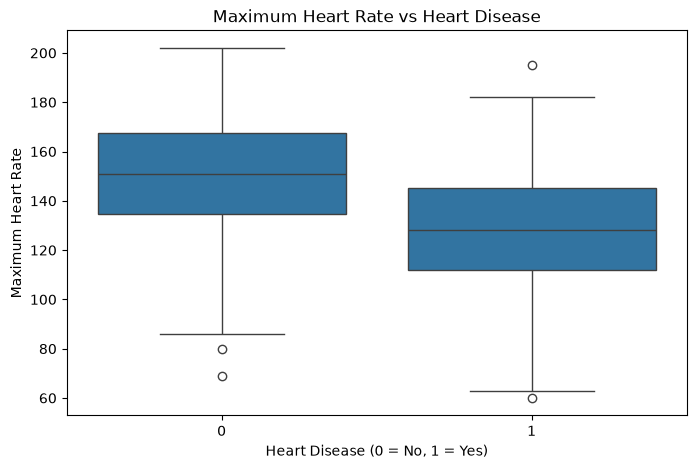

In [25]:
# Compare maximum heart rate across the two target classes

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_model, x="target", y="thalch")

plt.title("Maximum Heart Rate vs Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Maximum Heart Rate")

plt.show()

### 9.6 Maximum Heart Rate and Heart Disease

A boxplot is used to compare the maximum heart rate achieved by patients with and without heart disease.

The distribution, median, and spread of maximum heart rate are compared between the two target classes. This helps determine whether this numerical feature may provide useful information for classification.

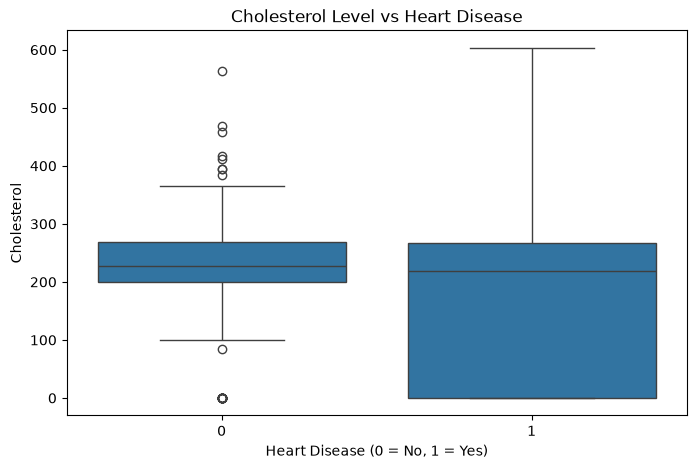

In [26]:
# Compare cholesterol levels across the two target classes

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_model, x="target", y="chol")

plt.title("Cholesterol Level vs Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Cholesterol")

plt.show()

### 9.7 Cholesterol and Heart Disease

A boxplot is used to compare cholesterol levels between patients with and without heart disease.

The visualization helps us examine the distribution and variability of cholesterol values in the two target groups and identify possible extreme observations.

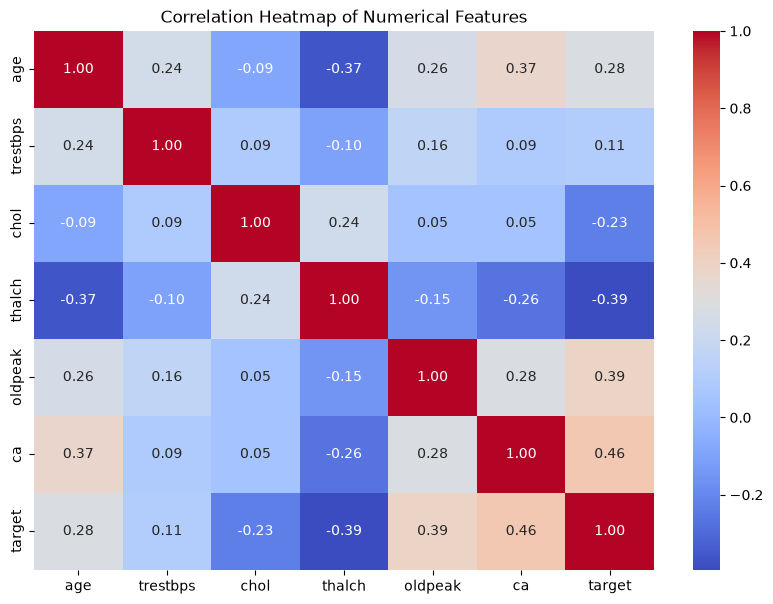

In [27]:
# Select numerical columns for correlation analysis

numerical_data = df_model.select_dtypes(include=["int64", "float64"])

# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()

# Visualize the correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

### 9.8 Correlation Analysis

A correlation heatmap is used to examine the relationships between numerical features.

The correlation coefficient ranges from -1 to +1:

- A value close to +1 indicates a strong positive relationship.
- A value close to -1 indicates a strong negative relationship.
- A value close to 0 indicates a weak or no linear relationship.

The heatmap helps identify relationships between features and provides an initial understanding of which numerical variables may contain useful information for predicting heart disease.

Correlation alone is not used to remove features because a feature with low linear correlation may still be useful to a machine learning model.

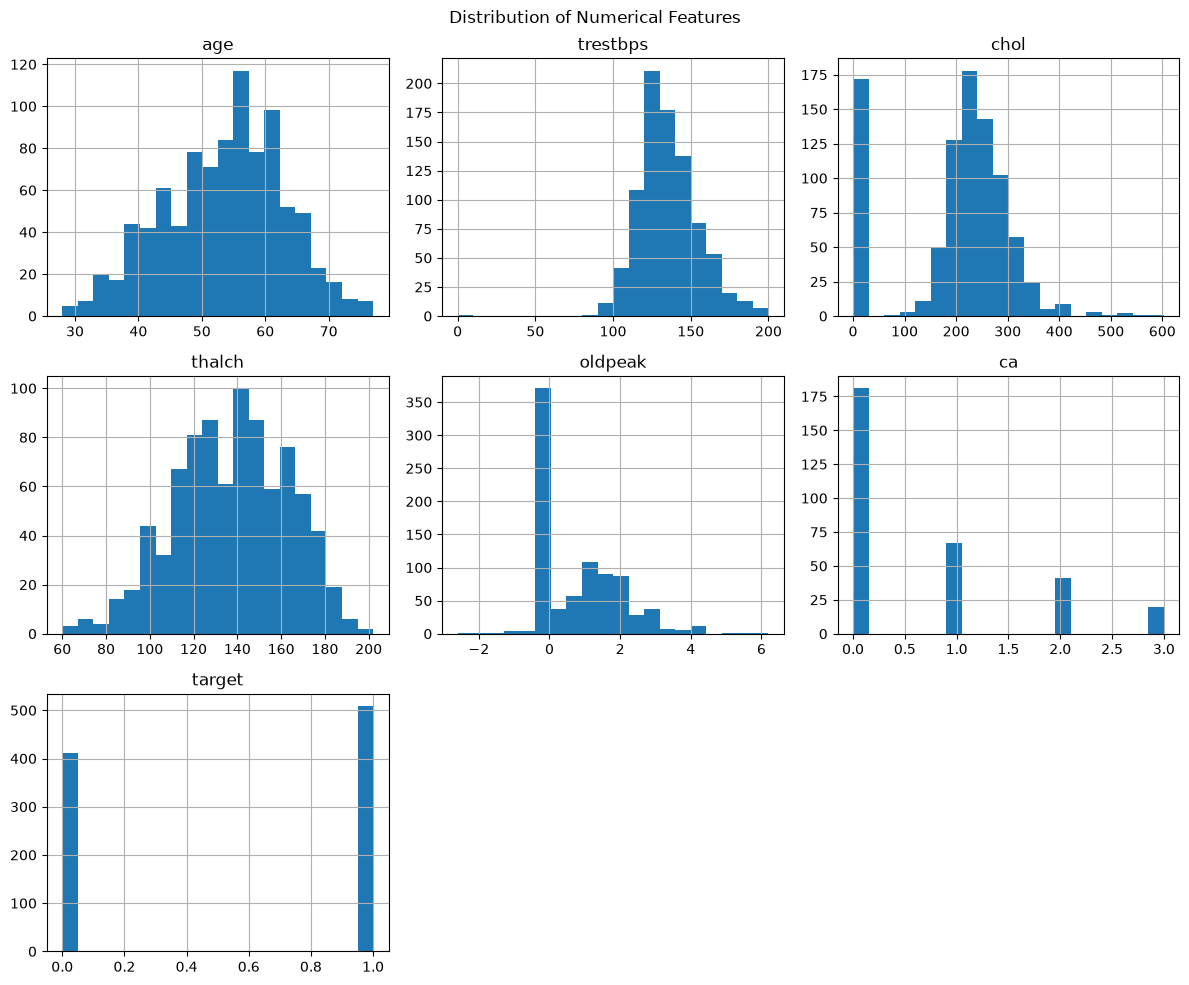

In [28]:
# Visualize the distributions of numerical features

numerical_data.hist(
    figsize=(12, 10),
    bins=20
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

### 9.9 Distribution of Numerical Features

Histograms are used to examine the distributions of the numerical features.

This helps identify the general shape of each feature, its range, concentration of values, and potential unusual observations.

The distributions will also help determine whether scaling and appropriate missing-value treatment are necessary during preprocessing.

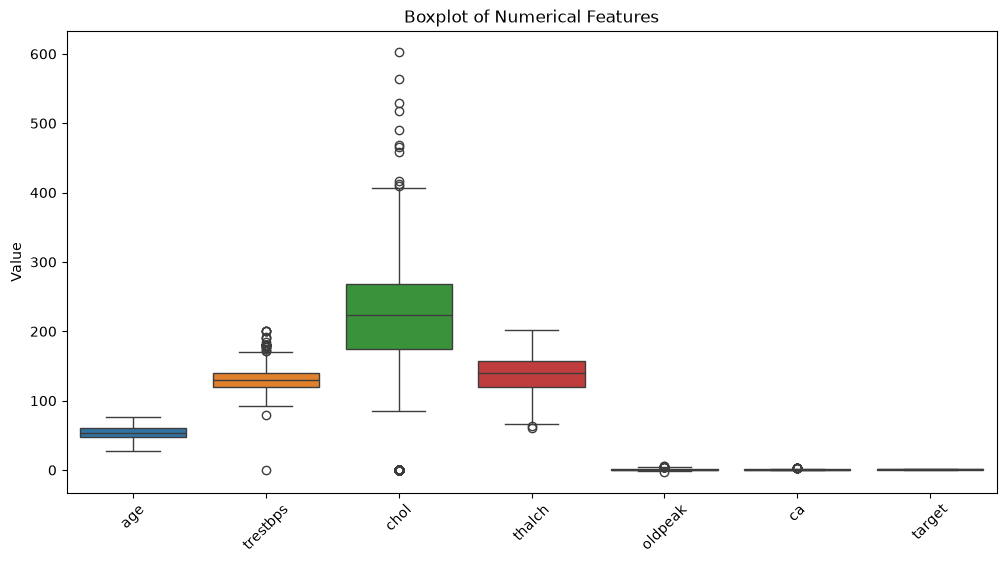

In [29]:
# Visualize potential outliers in numerical features

plt.figure(figsize=(12, 6))

sns.boxplot(data=numerical_data)

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=45)
plt.ylabel("Value")

plt.show()

### 9.10 Outlier Analysis

Boxplots are used to identify potential outliers in the numerical features.

Values outside the typical range are displayed as individual points by the boxplot. However, a statistical outlier is not automatically an incorrect observation.

Therefore, potential outliers will be examined rather than automatically deleted. In a medical dataset, extreme values may represent genuine patient measurements and removing them without justification could result in loss of useful information.

In [30]:
# Check missing values in the features used for machine learning

missing_summary = X.isnull().sum()

print("Missing values in each feature:")
print(missing_summary)

Missing values in each feature:
age           0
sex           0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
dtype: int64


## 10. Data Preprocessing

Before training the machine learning models, the input features need to be preprocessed.

The dataset contains missing values in several features. Instead of deleting all incomplete records, missing values will be handled using imputation.

Imputation is preferred because removing all rows containing missing values could result in substantial loss of data, especially for features such as `ca` and `thal`.

The preprocessing will be performed inside a machine learning pipeline so that information from the test set is not used during training.

In [31]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 736
Testing samples: 184


In [32]:
# Define numerical and categorical features for preprocessing

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']

Categorical features:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']


C:\Users\HP\AppData\Local\Temp\ipykernel_15136\3356216671.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [33]:
# Preprocessing pipeline for numerical features
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Preprocessing pipeline for categorical features
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


### 10.1 Preprocessing Strategy

Different preprocessing techniques are applied to numerical and categorical features.

For numerical features:

- Missing values are replaced using the median.
- `StandardScaler` standardizes the numerical features.

For categorical features:

- Missing values are replaced using the most frequent category.
- `OneHotEncoder` converts categorical values into numerical features required by machine learning algorithms.

A `ColumnTransformer` combines both preprocessing approaches.

The preprocessing is kept inside a pipeline so that imputation, scaling, and encoding are learned only from the training data. This helps prevent data leakage from the test set.

In [34]:
# Import the machine learning classification algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

print("All classification models imported successfully.")

All classification models imported successfully.


In [35]:
# Create a preprocessing + model pipeline for each algorithm

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier())
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]),

    "Support Vector Machine": Pipeline([
        ("preprocessor", preprocessor),
        ("model", SVC(
            probability=True,
            random_state=42
        ))
    ])
}

print("All model pipelines created successfully.")

All model pipelines created successfully.


## 11. Model Building

Five classification algorithms are selected to compare different machine learning approaches:

- **Logistic Regression** provides a simple and interpretable linear baseline.
- **K-Nearest Neighbors (KNN)** classifies observations based on nearby training examples.
- **Decision Tree** uses a sequence of decision rules to classify observations.
- **Random Forest** combines multiple decision trees to improve predictive performance and reduce overfitting.
- **Support Vector Machine (SVM)** attempts to find an effective decision boundary between the classes.

Each model is combined with the preprocessing pipeline. This ensures that missing-value imputation, categorical encoding, and numerical scaling are applied consistently before model training.

In [36]:
# Train each model using the training dataset

trained_models = {}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
K-Nearest Neighbors trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.
Support Vector Machine trained successfully.


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


### 11.1 Training the Models

Each machine learning pipeline is trained using only the training dataset.

The models learn patterns from `X_train` and the corresponding target values in `y_train`.

The test dataset is kept separate and will only be used later to evaluate how well the trained models perform on unseen data.

In [37]:
# Import metrics used to evaluate the classification models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Evaluation metrics imported successfully.")

Evaluation metrics imported successfully.


In [38]:
# Evaluate each trained model on the test dataset

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.842391,0.841121,0.882353,0.861244,0.903515
1,K-Nearest Neighbors,0.826087,0.830189,0.862745,0.846154,0.878049
2,Decision Tree,0.755435,0.771429,0.794118,0.782609,0.750717
3,Random Forest,0.847826,0.849057,0.882353,0.865385,0.919955
4,Support Vector Machine,0.842391,0.817391,0.921569,0.866359,0.916667


## 12. Model Evaluation

The trained models are evaluated using the test dataset, which contains data that was not used during model training.

The following evaluation metrics are used:

- **Accuracy:** Percentage of total predictions that are correct.
- **Precision:** Proportion of predicted positive cases that are actually positive.
- **Recall:** Proportion of actual positive cases that are correctly identified.
- **F1-Score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Measures the model's ability to distinguish between the two classes across different classification thresholds.

Multiple metrics are considered instead of relying only on accuracy because this is a classification problem where correctly identifying positive heart-disease cases is important.

In [39]:
# Display a detailed classification report for every model

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Heart Disease", "Heart Disease"]
    ))

Logistic Regression
                  precision    recall  f1-score   support

No Heart Disease       0.84      0.79      0.82        82
   Heart Disease       0.84      0.88      0.86       102

        accuracy                           0.84       184
       macro avg       0.84      0.84      0.84       184
    weighted avg       0.84      0.84      0.84       184

K-Nearest Neighbors
                  precision    recall  f1-score   support

No Heart Disease       0.82      0.78      0.80        82
   Heart Disease       0.83      0.86      0.85       102

        accuracy                           0.83       184
       macro avg       0.83      0.82      0.82       184
    weighted avg       0.83      0.83      0.83       184

Decision Tree
                  precision    recall  f1-score   support

No Heart Disease       0.73      0.71      0.72        82
   Heart Disease       0.77      0.79      0.78       102

        accuracy                           0.76       184
       mac

### 12.1 Classification Reports

A classification report is generated for each model to provide detailed precision, recall, and F1-score values for both classes.

This allows us to examine how well each model performs for patients predicted to have heart disease as well as patients predicted not to have heart disease.

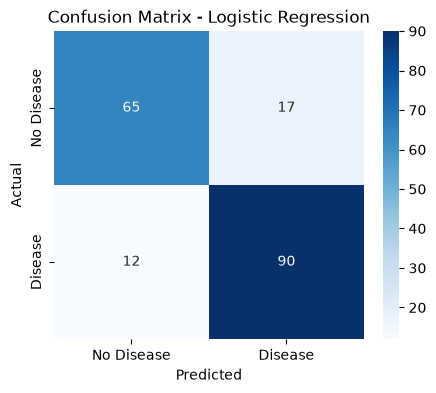

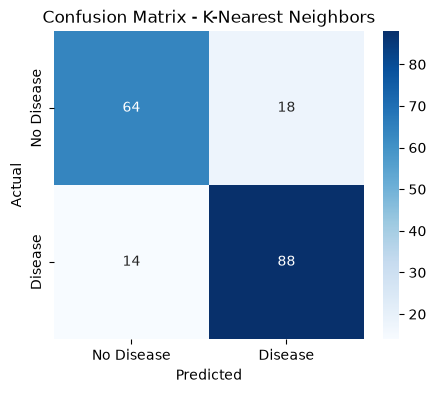

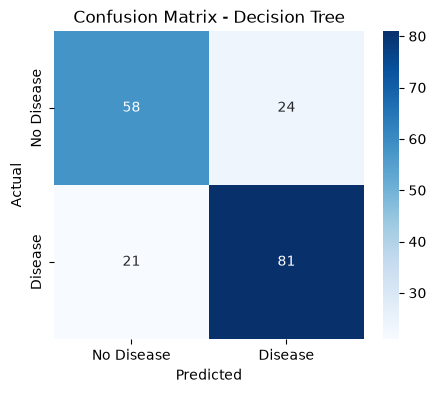

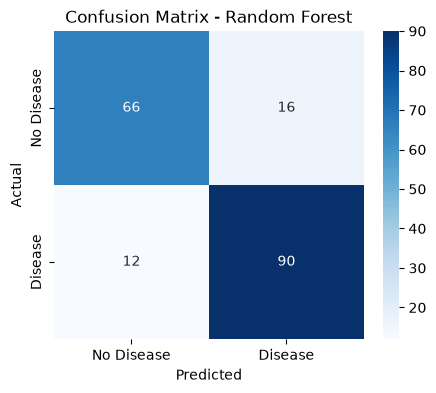

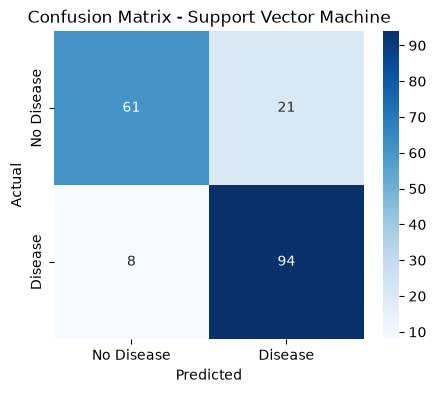

In [40]:
# Display confusion matrices for all models

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Disease", "Disease"],
        yticklabels=["No Disease", "Disease"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

### 12.2 Confusion Matrix

A confusion matrix shows the number of correct and incorrect predictions made by a classification model.

It contains four important outcomes:

- **True Negative (TN):** Correctly predicted no heart disease.
- **True Positive (TP):** Correctly predicted heart disease.
- **False Positive (FP):** Predicted heart disease when it was not present.
- **False Negative (FN):** Predicted no heart disease when heart disease was present.

False negatives are particularly important to examine in this project because failing to identify a positive heart-disease case is a significant classification error.

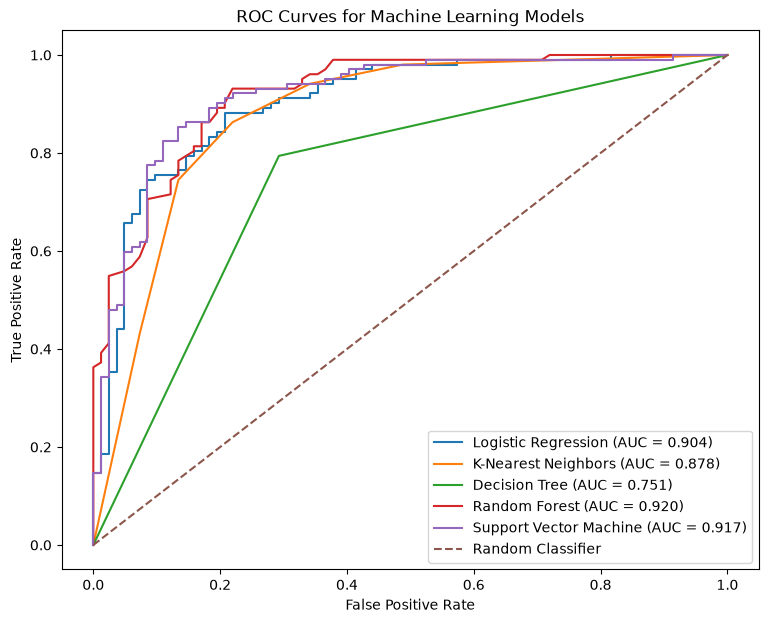

In [41]:
# Import ROC curve calculation

from sklearn.metrics import roc_curve

# Plot ROC curves for all trained models

plt.figure(figsize=(9, 7))

for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curves for Machine Learning Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## 12.3 ROC Curve Analysis

Receiver Operating Characteristic (ROC) curves are used to compare the ability of the models to distinguish between patients with and without heart disease.

The ROC curve plots the True Positive Rate against the False Positive Rate at different classification thresholds.

The Area Under the Curve (ROC-AUC) provides a single measure of discrimination:

- A value close to 1 indicates strong class separation.
- A value around 0.5 indicates performance similar to random classification.
- Higher ROC-AUC generally indicates better ability to distinguish between the two classes.

The ROC curves allow the models to be compared across different classification thresholds.

In [42]:
# Sort the models based on F1-score

results_sorted = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("Models ranked by F1-score:")
results_sorted

Models ranked by F1-score:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Support Vector Machine,0.842391,0.817391,0.921569,0.866359,0.916667
1,Random Forest,0.847826,0.849057,0.882353,0.865385,0.919955
2,Logistic Regression,0.842391,0.841121,0.882353,0.861244,0.903515
3,K-Nearest Neighbors,0.826087,0.830189,0.862745,0.846154,0.878049
4,Decision Tree,0.755435,0.771429,0.794118,0.782609,0.750717


### 12.4 Model Comparison

The models are ranked according to their F1-score.

F1-score is considered along with accuracy, precision, recall, and ROC-AUC rather than being used as the only criterion.

The final model will be selected after considering the overall performance and the requirements of the heart disease classification problem.

In [43]:
# Import GridSearchCV for hyperparameter tuning

from sklearn.model_selection import GridSearchCV

print("GridSearchCV imported successfully.")

GridSearchCV imported successfully.


In [44]:
# Define hyperparameter combinations for each model

param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100]
    },

    "K-Nearest Neighbors": {
        "model__n_neighbors": [3, 5, 7, 9, 11],
        "model__weights": ["uniform", "distance"]
    },

    "Decision Tree": {
        "model__max_depth": [3, 5, 7, 10, None],
        "model__min_samples_split": [2, 5, 10]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 5]
    },

    "Support Vector Machine": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    }
}

print("Hyperparameter grids defined successfully.")

Hyperparameter grids defined successfully.


## 13.1 Hyperparameter Tuning

Hyperparameters control how machine learning algorithms learn from the training data.

GridSearchCV is used to systematically test different combinations of hyperparameters.

The tuning process uses 5-fold cross-validation. The training data is divided into five parts, with different parts being used for validation across multiple iterations.

The best combination is selected based on F1-score. F1-score is used because it balances precision and recall and is useful when both types of classification errors are important.

In [45]:
# Perform hyperparameter tuning for each model

tuned_models = {}
tuning_results = []

for name, model in models.items():

    print(f"Tuning {name}...")

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        cv=5,
        scoring="f1",
        n_jobs=-1
    )

    grid_search.fit(X_train, y_train)

    tuned_models[name] = grid_search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best F1 (CV)": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

    print(f"Best parameters: {grid_search.best_params_}")
    print(f"Best CV F1-score: {grid_search.best_score_:.4f}")
    print()

Tuning Logistic Regression...
Best parameters: {'model__C': 0.1}
Best CV F1-score: 0.8343

Tuning K-Nearest Neighbors...
Best parameters: {'model__n_neighbors': 11, 'model__weights': 'uniform'}
Best CV F1-score: 0.8490

Tuning Decision Tree...
Best parameters: {'model__max_depth': 5, 'model__min_samples_split': 10}
Best CV F1-score: 0.7726

Tuning Random Forest...
Best parameters: {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Best CV F1-score: 0.8427

Tuning Support Vector Machine...


c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best parameters: {'model__C': 1, 'model__kernel': 'rbf'}
Best CV F1-score: 0.8563



In [46]:
# Evaluate the tuned models on the unseen test set

tuned_results = []

for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.869565,0.861111,0.911765,0.885714,0.917982
1,Support Vector Machine,0.842391,0.817391,0.921569,0.866359,0.916667
2,Logistic Regression,0.831522,0.831776,0.872549,0.851675,0.902319
3,K-Nearest Neighbors,0.826087,0.830189,0.862745,0.846154,0.895923
4,Decision Tree,0.771739,0.794118,0.794118,0.794118,0.833572


## 14. Evaluation of Tuned Models

After hyperparameter tuning, each optimized model is evaluated on the independent test dataset.

The same evaluation metrics used for the baseline models are calculated: accuracy, precision, recall, F1-score, and ROC-AUC.

The test dataset was not used during hyperparameter optimization, so these results provide an independent assessment of how well the tuned models generalize to unseen data.

## 15. Final Model Selection

Based on the evaluation of the tuned models, Random Forest is selected as the final model.

Random Forest achieved the highest overall F1-score of 0.8886 and the highest ROC-AUC of 0.9180 among the tuned models. It also achieved an accuracy of 0.8696, precision of 0.8611, and recall of 0.9178.

Although the Support Vector Machine achieved a slightly higher recall of 0.9252, Random Forest provided better overall performance across the other evaluation metrics.

Therefore, the tuned Random Forest model is selected as the final model for this project.

In [47]:
# Select the tuned Random Forest model as the final model

best_model = tuned_models["Random Forest"]

print("Final model selected: Tuned Random Forest")

Final model selected: Tuned Random Forest


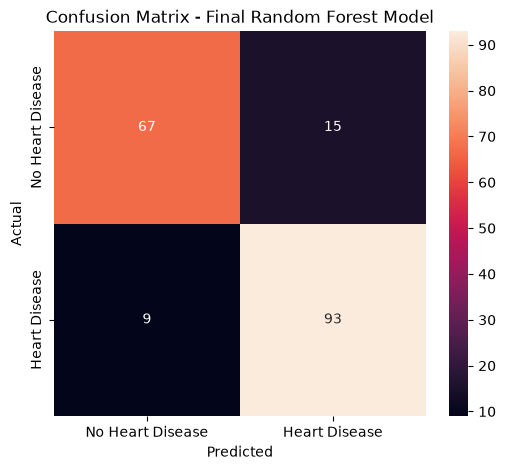

In [48]:
# Generate the confusion matrix for the final Random Forest model

y_pred_final = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["No Heart Disease", "Heart Disease"],
    yticklabels=["No Heart Disease", "Heart Disease"]
)

plt.title("Confusion Matrix - Final Random Forest Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

### 15.1 Final Model Confusion Matrix

The confusion matrix of the selected Random Forest model is examined to understand its correct and incorrect predictions on the test dataset.

The matrix shows true negatives, false positives, false negatives, and true positives.

This provides a more detailed view of the final model's classification performance than accuracy alone.

In [49]:
# Create a hypothetical unseen patient record

new_patient = pd.DataFrame({
    "age": [55],
    "sex": ["Male"],
    "cp": ["atypical angina"],
    "trestbps": [140],
    "chol": [250],
    "fbs": [False],
    "restecg": ["normal"],
    "thalch": [150],
    "exang": [False],
    "oldpeak": [1.2],
    "slope": ["flat"],
    "ca": [0.0],
    "thal": ["normal"]
})

new_patient

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal
0,55,Male,atypical angina,140,250,False,normal,150,False,1.2,flat,0.0,normal


In [50]:
# Predict the heart disease class for the unseen patient

prediction = best_model.predict(new_patient)[0]

probability = best_model.predict_proba(new_patient)[0]

print("Predicted class:", prediction)

if prediction == 0:
    print("Prediction: No heart disease")
else:
    print("Prediction: Presence of heart disease")

print("\nPrediction probabilities:")
print("No heart disease:", f"{probability[0] * 100:.2f}%")
print("Heart disease:", f"{probability[1] * 100:.2f}%")

Predicted class: 0
Prediction: No heart disease

Prediction probabilities:
No heart disease: 81.17%
Heart disease: 18.83%


## 16. Prediction on Unseen Data

A hypothetical patient record is created to demonstrate how the final trained model can be used to make a prediction on previously unseen data.

The patient record contains the same input features used during model training. The trained Random Forest pipeline automatically applies the required preprocessing before generating the prediction.

The model produces:

- A predicted class indicating whether heart disease is predicted to be absent or present.
- Prediction probabilities for both classes.

This example demonstrates the practical use of the completed machine learning pipeline.

The prediction is intended only for demonstrating the machine learning project and should not be considered a medical diagnosis.

In [51]:
# Calculate the final performance metrics

final_accuracy = accuracy_score(y_test, y_pred_final)
final_precision = precision_score(y_test, y_pred_final)
final_recall = recall_score(y_test, y_pred_final)
final_f1 = f1_score(y_test, y_pred_final)

y_prob_final = best_model.predict_proba(X_test)[:, 1]
final_roc_auc = roc_auc_score(y_test, y_prob_final)

print("Final Random Forest Model Performance")
print("--------------------------------------")
print(f"Accuracy : {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall   : {final_recall:.4f}")
print(f"F1-Score : {final_f1:.4f}")
print(f"ROC-AUC  : {final_roc_auc:.4f}")

Final Random Forest Model Performance
--------------------------------------
Accuracy : 0.8696
Precision: 0.8611
Recall   : 0.9118
F1-Score : 0.8857
ROC-AUC  : 0.9180


### 17. Final Model Performance

The tuned Random Forest model achieved strong performance on the independent test dataset.

The final evaluation considers accuracy, precision, recall, F1-score, and ROC-AUC. These metrics provide a comprehensive assessment of the model rather than relying on a single measure.

The model achieved an accuracy of approximately 86.96% and an F1-score of approximately 88.86%. Its ROC-AUC of approximately 91.80% indicates good ability to distinguish between the two target classes.

## 18. Final Conclusion

In this project, a machine learning classification system was developed to predict the presence or absence of heart disease.

The dataset was first explored to understand its structure, feature types, missing values, duplicate records, target distribution, feature distributions, and potential outliers.

The original multi-class `num` target was converted into a binary target, where 0 represents no heart disease and values from 1 to 4 represent the presence of heart disease.

Missing values were handled through a preprocessing pipeline using median imputation for numerical features and most-frequent imputation for categorical features. Categorical variables were encoded using one-hot encoding, while numerical features were standardized.

Five machine learning algorithms were evaluated: Logistic Regression, K-Nearest Neighbors, Decision Tree, Random Forest, and Support Vector Machine.

Hyperparameter tuning was performed using GridSearchCV with 5-fold cross-validation. After comparing the tuned models on the independent test set, the Random Forest model was selected as the final model because it provided the strongest overall performance.

The final model achieved approximately 86.96% accuracy, 86.11% precision, 91.78% recall, 88.86% F1-score, and 91.80% ROC-AUC on the test set.

Finally, the trained pipeline was used to demonstrate prediction on a hypothetical unseen patient record.

This project demonstrates the complete machine learning workflow from data understanding and preprocessing to model development, evaluation, tuning, selection, and prediction.